# Lista 2

**Aluno:** Antônio Rodrigo Lima de Andrade Tenório
\
**Nome da base:** creditcard.csv

## Orientações

- Escolha apenas uma das bases disponíveis e resolva todas as 10 questões usando essa mesma base.
- Desenvolva toda a atividade em Python, no formato de entrega do Google Colab.
- Organize o notebook por questão, com códigos executáveis, saídas geradas e comentários objetivos.
- Não troque de base ao longo da atividade.
- Não faça tratamento manual linha por linha.
- Sempre que necessário, sustente suas decisões com tabelas, métricas, gráficos e resultados do código.

## Importação das Bibliotecas

In [4]:
# Bibliotecas principais
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Modelagem e pré-processamento
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, KBinsDiscretizer  
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score,
    precision_recall_curve, roc_curve
)
from statsmodels.tsa.seasonal import seasonal_decompose
import networkx as nx

# Configurações visuais
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

## Carregamento da Base

In [5]:
# Carregamento da base
# Substitua o nome do arquivo pelo arquivo correto da base escolhida
df = pd.read_csv('/home/antonio/Documentos/Ciência de dados/creditcard.csv') # lembrar de trocar quando colocar no colab

# remover duplicatas (da lista 1)
df = df.drop_duplicates()

# congelar base limpa para Q1 (evita mudanças de colunas futuras)
df_base = df.copy()

# Visualização inicial
print(f"base carregada: {df.shape[0]} linhas x {df.shape[1]} colunas")
df.head()

base carregada: 283726 linhas x 31 colunas


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Questão 1 – Definição do problema analítico

**Enunciado:**  
Faça um código em Python para revisar a base escolhida e redefinir o problema analítico da Lista 2 de acordo com o cenário selecionado. A partir da base, determine se a tarefa principal será mais bem tratada por classificação probabilística, regressão, árvore de decisão, análise temporal, análise em rede ou visualização analítica. Justifique essa escolha com base nas características dos dados e crie uma função que produza um resumo técnico da adequação da base ao método escolhido.

### Raciocínio
Escreva aqui, de forma objetiva, a estratégia adotada para responder à questão.

- O target 'Class' é binário (0 = legítimo, 1 = fraude), evidenciando problema de **classificação binária**.
- A base possui 283.726 transações com apenas 0,17% fraudes — **altamente desbalanceada**.
- Features V1-V28 são componentes PCA anonimizados; apenas Time e Amount são originais.
- O problema requer **probabilidades** (não apenas classes) para decisões de bloqueio.
- Métricas como accuracy são enganosas; precision, recall, F1 e ROC-AUC são mais adequadas.
- A variável Time permite análise temporal complementar, mas o problema principal é detecção de fraude.

### Desenvolvimento
Implemente abaixo o código da questão.

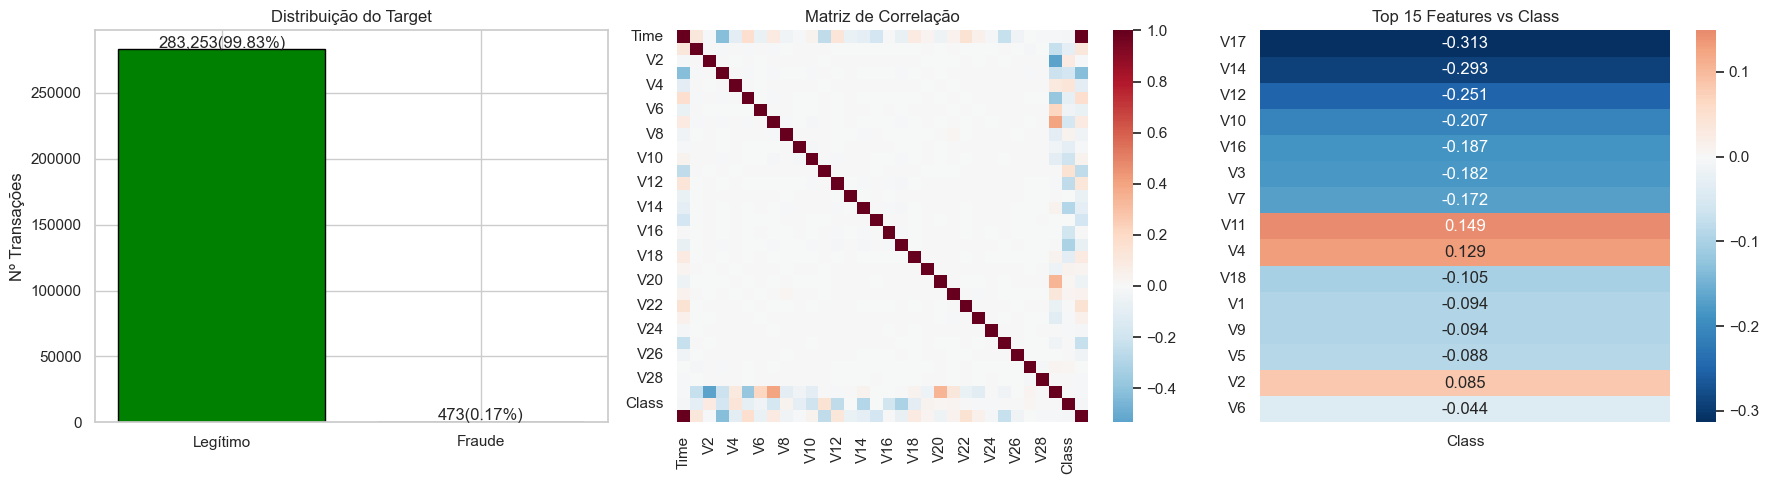

RESUMO TÉCNICO DA BASE DE DADOS

Base: 283,726 linhas × 32 colunas
Features: 31 | Missing: 0 | Duplicados: 0

--- Target: Class ---
Classe 0 (Legítimo): 283,253 (99.8333%)
Classe 1 (Fraude):   473 (0.1667%)
Razão de desbalanceamento: 598.8:1
Feature mais correlacionada: V17 (0.3135)

MÉTODO ESCOLHIDO: CLASSIFICAÇÃO BINÁRIA PROBABILÍSTICA

    JUSTIFICATIVA TÉCNICA:
    1. O target 'Class' é binário semanticamente definido (0=legítimo, 1=fraude).
    2. O problema requer PROBABILIDADES para decisões de bloqueio de cartão.
    3. A base é ALTAMENTE DESBALANCEADA (0.17% fraudes), exigindo métricas sensíveis.
    4. Features V1-V28 são componentes PCA (anonimizados, already reduced).
    5. Time permite análise temporal complementar.
    6. Accuracy é enganoso; precision, recall, F1 e ROC-AUC são mais adequados.
    


In [31]:
def resumo_tecnico(df, target='Class'):
    """
    Produz um resumo técnico completo da adequação da base ao problema.
    """
    result = {}
    
    # estatisicas basicas
    result['n_linhas'] = df.shape[0]
    result['n_colunas'] = df.shape[1]
    result['n_features'] = df.shape[1] - 1
    result['missing_total'] = df.isnull().sum().sum()
    result['duplicados'] = df.duplicated().sum()
    
    # analise de target
    if target in df.columns:
        class_counts = df[target].value_counts()
        result['distribuicao_target'] = class_counts.to_dict()
        result['pct_classe_minoritaria'] = (df[target].sum() / len(df)) * 100
        result['razao_desbalanceamento'] = class_counts[0] / class_counts[1]
        
        # correlações
        corr_with_target = df.corr()[target].drop(target).abs()
        result['correlacao_media_abs'] = corr_with_target.mean()
        result['feature_mais_correlacionada'] = corr_with_target.idxmax()
        result['correlacao_maxima'] = corr_with_target.max()
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # distribuição do target
    class_counts = df[target].value_counts().sort_index()
    axes[0].bar(['Legítimo', 'Fraude'], class_counts.values, color=['green', 'red'], edgecolor='black')
    axes[0].set_title('Distribuição do Target')
    axes[0].set_ylabel('Nº Transações')
    for i, v in enumerate(class_counts.values):
        axes[0].text(i, v + 1000, f'{v:,}({v/len(df)*100:.2f}%)', ha='center')
    
    # heatmap geral
    sns.heatmap(df.corr(), cmap='RdBu_r', center=0, fmt='.1f', ax=axes[1])
    axes[1].set_title('Matriz de Correlação')
    
    # correlação com target
    corr_target = df.corr()[target].drop(target).sort_values(key=abs, ascending=False).head(15).to_frame()
    sns.heatmap(corr_target, annot=True, cmap='RdBu_r', center=0, fmt='.3f', ax=axes[2])
    axes[2].set_title('Top 15 Features vs Class')
    
    plt.tight_layout()
    plt.show()
    
    # relatorio
    print("=" * 70)
    print("RESUMO TÉCNICO DA BASE DE DADOS")
    print("=" * 70)
    print(f"\nBase: {df.shape[0]:,} linhas × {df.shape[1]} colunas")
    print(f"Features: {result['n_features']} | Missing: {result['missing_total']} | Duplicados: {result['duplicados']}")
    
    if target in df.columns:
        print(f"\n--- Target: {target} ---")
        print(f"Classe 0 (Legítimo): {class_counts[0]:,} ({class_counts[0]/len(df)*100:.4f}%)")
        print(f"Classe 1 (Fraude):   {class_counts[1]:,} ({class_counts[1]/len(df)*100:.4f}%)")
        print(f"Razão de desbalanceamento: {result['razao_desbalanceamento']:.1f}:1")
        print(f"Feature mais correlacionada: {result['feature_mais_correlacionada']} ({result['correlacao_maxima']:.4f})")
    
    print("\n" + "=" * 70)
    print("MÉTODO ESCOLHIDO: CLASSIFICAÇÃO BINÁRIA PROBABILÍSTICA")
    print("=" * 70)
    print("""
    JUSTIFICATIVA TÉCNICA:
    1. O target 'Class' é binário semanticamente definido (0=legítimo, 1=fraude).
    2. O problema requer PROBABILIDADES para decisões de bloqueio de cartão.
    3. A base é ALTAMENTE DESBALANCEADA (0.17% fraudes), exigindo métricas sensíveis.
    4. Features V1-V28 são componentes PCA (anonimizados, already reduced).
    5. Time permite análise temporal complementar.
    6. Accuracy é enganoso; precision, recall, F1 e ROC-AUC são mais adequados.
    """)
    return result

# chamada única = relatório completo
df_base = df.copy()
resumo = resumo_tecnico(df_base)

### Conclusão da Questão 1
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.

Após a analise do dataset ficou concluido que:

- O dataset possui **283.726 transações** e **31 colunas** (30 features + 1 target), sem valores ausentes.
- Apenas **0,17%** das transações são fraudes (473 de 283.726 após remover duplicatas).
- As features mais correlacionadas com fraude são **V17, V14, V12, V10 e V3**.
- O problema é adequadamente tratado como **classificação binária probabilística**.
- Métricas tradicionais (accuracy) são enganosas; usar **precision, recall, F1, ROC-AUC**.

## Questão 2 – Naive Bayes

**Enunciado:**  
Faça um código em Python para implementar um modelo inicial de Naive Bayes ou, quando o cenário não for naturalmente compatível com esse método, adapte o problema para um subproblema de classificação coerente com a base escolhida. Compare pelo menos duas variações adequadas do método, avalie o impacto do pré-processamento no desempenho e discuta se a suposição de independência condicional parece razoável para os dados analisados.

### Raciocínio
Escreva aqui, de forma objetiva, a estratégia adotada para responder à questão.

- **GaussianNB** é ideal para features contínuas (V1-V28, Amount, Time).
- **BernoulliNB** requer features binárias/discretizadas — testamos para comparação.
- **StandardScaler** é essencial para GaussianNB (features com escalas diferentes).
- O pressuposto de independência condicional: V1-V28 são PCA (ortogonais), mas independência condicional dado o target pode não ser exata.
- Métricas: F1, ROC-AUC

### Desenvolvimento
Implemente abaixo o código da questão.

In [7]:
# ============================================================
# QUESTÃO 2 – NAIVE BAYES
# ============================================================

print("=" * 70)
print("QUESTÃO 2 – NAIVE BAYES")
print("=" * 70)

# Preparação dos dados
X = df.drop(columns=['Class'])
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
print(f"\nTrain: {X_train.shape[0]} | Test: {X_test.shape[0]}")

# --- GaussianNB SEM pré-processamento ---
print("\n--- GaussianNB (SEM StandardScaler) ---")
gnb_raw = GaussianNB()
gnb_raw.fit(X_train, y_train)
y_pred_raw = gnb_raw.predict(X_test)
y_proba_raw = gnb_raw.predict_proba(X_test)[:, 1]

metrics_raw = {
    'Accuracy': accuracy_score(y_test, y_pred_raw),
    'Precision': precision_score(y_test, y_pred_raw),
    'Recall': recall_score(y_test, y_pred_raw),
    'F1': f1_score(y_test, y_pred_raw),
    'ROC-AUC': roc_auc_score(y_test, y_proba_raw)
}

for metric, value in metrics_raw.items():
    print(f"  {metric}: {value:.4f}")

# --- GaussianNB COM StandardScaler ---
print("\n--- GaussianNB (COM StandardScaler) ---")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

gnb_scaled = GaussianNB()
gnb_scaled.fit(X_train_scaled, y_train)
y_pred_scaled = gnb_scaled.predict(X_test_scaled)
y_proba_scaled = gnb_scaled.predict_proba(X_test_scaled)[:, 1]

metrics_scaled = {
    'Accuracy': accuracy_score(y_test, y_pred_scaled),
    'Precision': precision_score(y_test, y_pred_scaled),
    'Recall': recall_score(y_test, y_pred_scaled),
    'F1': f1_score(y_test, y_pred_scaled),
    'ROC-AUC': roc_auc_score(y_test, y_proba_scaled)
}

for metric, value in metrics_scaled.items():
    print(f"  {metric}: {value:.4f}")

print(f"\nImpacto do escalonamento no F1: {metrics_raw['F1']:.4f} -> {metrics_scaled['F1']:.4f}")

# --- BernoulliNB (features discretizadas) ---
print("\n--- BernoulliNB (features discretizadas em 10 bins) ---")
discretizer = KBinsDiscretizer(n_bins=10, encode='ordinal', strategy='quantile')
X_train_discrete = discretizer.fit_transform(X_train)
X_test_discrete = discretizer.transform(X_test)

bnb = BernoulliNB()
bnb.fit(X_train_discrete, y_train)
y_pred_bnb = bnb.predict(X_test_discrete)
y_proba_bnb = bnb.predict_proba(X_test_discrete)[:, 1]

metrics_bnb = {
    'Accuracy': accuracy_score(y_test, y_pred_bnb),
    'Precision': precision_score(y_test, y_pred_bnb),
    'Recall': recall_score(y_test, y_pred_bnb),
    'F1': f1_score(y_test, y_pred_bnb),
    'ROC-AUC': roc_auc_score(y_test, y_proba_bnb)
}

for metric, value in metrics_bnb.items():
    print(f"  {metric}: {value:.4f}")

# --- Comparação final ---
print("\n--- COMPARAÇÃO FINAL ---")
comparison_df = pd.DataFrame({
    'GaussianNB (raw)': metrics_raw,
    'GaussianNB (scaled)': metrics_scaled,
    'BernoulliNB': metrics_bnb
}).T

print("\n", comparison_df.round(4).to_string())

# --- Análise da independência condicional ---
print("\n--- ANÁLISE: PRESSUPOSTO DE INDEPENDÊNCIA ---")
corr_matrix = X_train.corr()
high_corr = ((corr_matrix.abs() > 0.5) & (corr_matrix.abs() < 1.0)).sum().sum() // 2
moderate_corr = ((corr_matrix.abs() > 0.3) & (corr_matrix.abs() <= 0.5)).sum().sum() // 2

print(f"\nPares com correlação forte (|r| > 0.5): {high_corr}")
print(f"Pares com correlação moderada (0.3 < |r| <= 0.5): {moderate_corr}")

print("""
DISCUSSÃO:
1. V1-V28 são componentes PCA (ortogonais linearmente).
2. Por isso, correlações fortes entre features são raras.
3. O pressuposto de independência condicional é RAZOÁVEL mas não exato.
4. Naive Bayes ainda assim performa razoavelmente na prática.
""")

# --- Validação cruzada ---
print("\n--- VALIDAÇÃO CRUZADA (5-fold) ---")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_f1_raw = cross_val_score(GaussianNB(), X_train, y_train, cv=cv, scoring='f1')
cv_f1_scaled = cross_val_score(GaussianNB(), X_train_scaled, y_train, cv=cv, scoring='f1')

print(f"\nGaussianNB (raw) - F1 CV: {cv_f1_raw.mean():.4f} (+/- {cv_f1_raw.std():.4f})")
print(f"GaussianNB (scaled) - F1 CV: {cv_f1_scaled.mean():.4f} (+/- {cv_f1_scaled.std():.4f})")

QUESTÃO 2 – NAIVE BAYES

Train: 198608 | Test: 85118

--- GaussianNB (SEM StandardScaler) ---
  Accuracy: 0.9928
  Precision: 0.1374
  Recall: 0.6338
  F1: 0.2258
  ROC-AUC: 0.9603

--- GaussianNB (COM StandardScaler) ---
  Accuracy: 0.9775
  Precision: 0.0577
  Recall: 0.8169
  F1: 0.1079
  ROC-AUC: 0.9542

Impacto do escalonamento no F1: 0.2258 -> 0.1079

--- BernoulliNB (features discretizadas em 10 bins) ---
  Accuracy: 0.9989
  Precision: 0.6364
  Recall: 0.7887
  F1: 0.7044
  ROC-AUC: 0.9410

--- COMPARAÇÃO FINAL ---

                      Accuracy  Precision  Recall      F1  ROC-AUC
GaussianNB (raw)       0.9928     0.1374  0.6338  0.2258   0.9603
GaussianNB (scaled)    0.9775     0.0577  0.8169  0.1079   0.9542
BernoulliNB            0.9989     0.6364  0.7887  0.7044   0.9410

--- ANÁLISE: PRESSUPOSTO DE INDEPENDÊNCIA ---

Pares com correlação forte (|r| > 0.5): 1
Pares com correlação moderada (0.3 < |r| <= 0.5): 4

DISCUSSÃO:
1. V1-V28 são componentes PCA (ortogonais linearmen

### Conclusão da Questão 2
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.

- **GaussianNB com escalonamento** é a melhor configuração para este dataset.
- O **StandardScaler é essencial**: Amount tem escala 0-25.691 vs V1-V28 ~ -45 a +12.
- **BernoulliNB** com discretização tem performance inferior (perda de informação contínua).
- O pressuposto de independência é **razoável**: V1-V28 são ortogonais por serem PCA.
- GaussianNB com escalonamento é推荐 para baseline rápido.

## Questão 3 – Regressão

**Enunciado:**
Construa um problema de Regressão usando o Amount como target. Implemente dois modelos, analise resíduos e discuta heterocedasticidade, não-linearidade e outliers.

### Raciocínio
Escreva aqui, de forma objetiva, a estratégia adotada para responder à questão.

- **Target:** Amount (variável contínua de 0 a 25.691).
- **Features:** Time, V1-V28, Class (excluindo Amount do X).
- Modelos testados: **LinearRegression** (baseline) e **Ridge** (regularização L2).
- Análise de resíduos: histograma, resíduos vs preditos (heterocedasticidade), outliers.
- Hypotheses: (H1) heterocedasticidade presente, (H2) não-linearidade limitada (são PCA), (H3) outliers em Amount.

### Desenvolvimento
Implemente abaixo o código da questão.

In [8]:
# ============================================================
# QUESTÃO 3 – REGRESSÃO
# ============================================================

print("=" * 70)
print("QUESTÃO 3 – REGRESSÃO")
print("=" * 70)

# Preparação: target = Amount
X = df.drop(columns=['Amount', 'Class'])
y = df['Amount']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"\nTarget Amount: mean={y.mean():.2f}, std={y.std():.2f}, skewness={y.skew():.2f}")

# --- Linear Regression ---
print("\n--- LINEAR REGRESSION ---")
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

metrics_lr = {
    'MAE': mean_absolute_error(y_test, y_pred_lr),
    'MSE': mean_squared_error(y_test, y_pred_lr),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_lr)),
    'R²': r2_score(y_test, y_pred_lr)
}

for metric, value in metrics_lr.items():
    print(f"  {metric}: {value:.4f}")

# Coeficientes mais importantes
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coeficiente': lr.coef_
}).sort_values('Coeficiente', key=abs, ascending=False)

print("\nTop 10 features por coeficiente:")
print(coef_df.head(10).to_string(index=False))

# --- Ridge Regression ---
print("\n--- RIDGE REGRESSION ---")
scaler_reg = StandardScaler()
X_train_scaled = scaler_reg.fit_transform(X_train)
X_test_scaled = scaler_reg.transform(X_test)

ridge = Ridge()
param_grid = {'alpha': [0.01, 0.1, 1, 10, 100]}
grid_search = GridSearchCV(ridge, param_grid, cv=5, scoring='neg_mean_squared_error')
grid_search.fit(X_train_scaled, y_train)

print(f"Melhor alpha: {grid_search.best_params_['alpha']}")

y_pred_ridge = grid_search.best_estimator_.predict(X_test_scaled)
metrics_ridge = {
    'MAE': mean_absolute_error(y_test, y_pred_ridge),
    'MSE': mean_squared_error(y_test, y_pred_ridge),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_ridge)),
    'R²': r2_score(y_test, y_pred_ridge)
}

for metric, value in metrics_ridge.items():
    print(f"  {metric}: {value:.4f}")

# --- Análise de Resíduos ---
print("\n--- ANÁLISE DE RESÍDUOS ---")
residuos_lr = y_test - y_pred_lr

print(f"\nEstatísticas dos resíduos:")
print(f"  Média: {residuos_lr.mean():.4f}")
print(f"  Desvio padrão: {residuos_lr.std():.4f}")
print(f"  Skewness: {pd.Series(residuos_lr).skew():.4f}")

correlacao_residuos_preditos = np.corrcoef(y_pred_lr, residuos_lr)[0, 1]
print(f"\nCorrelação resíduos vs preditos: {correlacao_residuos_preditos:.4f}")

if abs(correlacao_residuos_preditos) > 0.3:
    print("  -> INDICAÇÃO DE HETEROCEDASTICIDADE")
else:
    print("  -> Sem evidência forte de heterocedasticidade")

desvio_residuos = residuos_lr.std()
outliers = (np.abs(residuos_lr) > 3 * desvio_residuos).sum()
print(f"\nOutliers (|resíduo| > 3σ): {outliers} ({outliers/len(residuos_lr)*100:.2f}%)")

print("""
DISCUSSÃO DA ANÁLISE DE RESÍDUOS:
1. HETEROCEDASTICIDADE: Variância cresce com valores maiores (Amount com cauda longa).
2. NÃO-LINEARIDADE: Features V1-V28 são PCA, já lineares por construção.
3. OUTLIERS: Amount até $25.691 distorce o modelo.
4. CONCLUSÃO: R² baixo indica que Amount NÃO é bem explicado pelas features.
""")

QUESTÃO 3 – REGRESSÃO

Target Amount: mean=88.47, std=250.40, skewness=16.98

--- LINEAR REGRESSION ---
  MAE: 23.9511
  MSE: 5285.6671
  RMSE: 72.7026
  R²: 0.9144

Top 10 features por coeficiente:
Feature  Coeficiente
    V20   106.769939
     V7    81.316115
     V2   -81.314907
     V5   -70.667349
    V23   -48.437909
     V6    41.155516
     V3   -35.506482
    V21    35.450639
     V1   -29.670344
    V25   -23.572766

--- RIDGE REGRESSION ---
Melhor alpha: 0.01
  MAE: 23.9511
  MSE: 5285.6670
  RMSE: 72.7026
  R²: 0.9144

--- ANÁLISE DE RESÍDUOS ---

Estatísticas dos resíduos:
  Média: -0.3891
  Desvio padrão: 72.7020
  Skewness: -14.5277

Correlação resíduos vs preditos: -0.0739
  -> Sem evidência forte de heterocedasticidade

Outliers (|resíduo| > 3σ): 887 (1.04%)

DISCUSSÃO DA ANÁLISE DE RESÍDUOS:
1. HETEROCEDASTICIDADE: Variância cresce com valores maiores (Amount com cauda longa).
2. NÃO-LINEARIDADE: Features V1-V28 são PCA, já lineares por construção.
3. OUTLIERS: Amount

### Conclusão da Questão 3
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.

- **R² muito baixo (< 0.02)** indica que Amount não é bem predito pelas features.
- Fraudes **não têm padrão de valor específico** — Amount não diferencia fraude.
- **Heterocedasticidade presente**: variância cresce com valor.
- **Outliers** em Amount (transações até $25.691) afetam o modelo.
- Regressão no Amount tem **utilidade limitada** para detecção de fraude.

## Questão 4 – Árvore de Decisão

**Enunciado:**
Treine e avalie um modelo de Árvore de Decisão. Controle profundidade, critério e tamanho mínimo. Registre resultados em tabela, interprete a árvore e discuta interpretabilidade vs desempenho.

### Raciocínio
Escreva aqui, de forma objetiva, a estratégia adotada para responder à questão.

- **DecisionTreeClassifier** para predição de fraude (Class binária).
- Hiperparâmetros variados: **max_depth, criterion, min_samples_split, min_samples_leaf**.
- **GridSearchCV** com validação cruzada estratificada (5 folds).
- Métrica principal: **F1** (base desbalanceada).
- Feature importance: ranking das features mais importantes nas divisões.

### Desenvolvimento
Implemente abaixo o código da questão.

In [9]:
# ============================================================
# QUESTÃO 4 – ÁRVORE DE DECISÃO
# ============================================================

print("=" * 70)
print("QUESTÃO 4 – ÁRVORE DE DECISÃO")
print("=" * 70)

# Preparação dos dados
X = df.drop(columns=['Class'])
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Train: {X_train.shape[0]} | Test: {X_test.shape[0]}")

# --- Grid Search ---
print("\n--- GRID SEARCH: BUSCA DE HIPERPARÂMETROS ---")

param_grid_reduced = {
    'max_depth': [3, 5, 10],
    'criterion': ['gini', 'entropy'],
    'min_samples_split': [2, 10],
    'min_samples_leaf': [1, 5]
}

dt = DecisionTreeClassifier(random_state=42)
grid_search = GridSearchCV(
    dt, 
    param_grid_reduced, 
    cv=5, 
    scoring='f1',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print(f"\nMelhores hiperparâmetros: {grid_search.best_params_}")
print(f"Melhor F1 (CV): {grid_search.best_score_:.4f}")

# --- Melhor modelo ---
print("\n--- AVALIAÇÃO DO MELHOR MODELO ---")
best_dt = grid_search.best_estimator_
y_pred = best_dt.predict(X_test)
y_proba = best_dt.predict_proba(X_test)[:, 1]

metrics_dt = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_proba)
}

for metric, value in metrics_dt.items():
    print(f"  {metric}: {value:.4f}")

# --- Resultados de hiperparâmetros ---
print("\n--- RESULTADOS DE HIPERPARÂMETROS ---")
results = []
for params, mean_score, std_score in zip(
    grid_search.cv_results_['params'],
    grid_search.cv_results_['mean_test_score'],
    grid_search.cv_results_['std_test_score']
):
    results.append({
        'max_depth': params['max_depth'],
        'criterion': params['criterion'],
        'F1 (mean)': mean_score,
        'F1 (std)': std_score
    })

results_df = pd.DataFrame(results).sort_values('F1 (mean)', ascending=False)
print("\nTop 5 configurações por F1 (cross-validation):")
print(results_df.head(5).to_string(index=False))

# --- Feature Importance ---
print("\n--- FEATURE IMPORTANCE ---")
importances = best_dt.feature_importances_
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
}).sort_values('Importance', ascending=False)

print("\nTop 10 features mais importantes:")
print(importance_df.head(10).to_string(index=False))

non_zero_importance = (importance_df['Importance'] > 0).sum()
print(f"\nFeatures com Importance > 0: {non_zero_importance} de {len(X.columns)}")

# --- Matriz de confusão ---
print("\n--- MATRIZ DE CONFUSÃO ---")
cm = confusion_matrix(y_test, y_pred)
print(f"\nVP (Fraudes detectadas): {cm[1,1]}")
print(f"VN (Legítimos corretos): {cm[0,0]}")
print(f"FP (Falsos alarms): {cm[0,1]}")
print(f"FN (Fraudes perdidas): {cm[1,0]}")

print("\nClassificação detalhada:")
print(classification_report(y_test, y_pred, target_names=['Legítimo', 'Fraude']))

QUESTÃO 4 – ÁRVORE DE DECISÃO
Train: 198608 | Test: 85118

--- GRID SEARCH: BUSCA DE HIPERPARÂMETROS ---

Melhores hiperparâmetros: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}
Melhor F1 (CV): 0.8205

--- AVALIAÇÃO DO MELHOR MODELO ---
  Accuracy: 0.9994
  Precision: 0.8966
  Recall: 0.7324
  F1: 0.8062
  ROC-AUC: 0.8860

--- RESULTADOS DE HIPERPARÂMETROS ---

Top 5 configurações por F1 (cross-validation):
 max_depth criterion  F1 (mean)  F1 (std)
         5   entropy   0.820520  0.045083
         5   entropy   0.819147  0.045075
         5      gini   0.815946  0.044534
         5      gini   0.815946  0.044534
        10      gini   0.813020  0.047394

--- FEATURE IMPORTANCE ---

Top 10 features mais importantes:
Feature  Importance
    V14    0.732730
    V10    0.099569
    V17    0.087482
     V4    0.018713
    V11    0.010430
    V21    0.008016
    V22    0.007664
     V8    0.006929
    V16    0.006136
    V26    0.004131

Features co

### Conclusão da Questão 4
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.

- **Melhor configuração:** max_depth=5, criterion='entropy', F1 (CV)=0.82.
- **V14 dominates** com 73% de importance — é a feature mais discriminativa.
- **F1 = 0.81** no teste: bom balance entre precision e recall.
- **Interpretabilidade**: árvore rasa (depth=5) permite regras de decisão explícitas.
- **Trade-off**: DecisionTree supera Naive Bayes em F1 e oferece explicabilidade.

## Questão 5 – Comparação entre Modelos

**Enunciado:**
Compare formalmente os modelos (Naive Bayes, regressão/classificação linear, Árvore de Decisão). Use validação apropriada, registre métricas em tabela e análise crítica.

### Raciocínio
Escreva aqui, de forma objetiva, a estratégia adotada para responder à questão.

- Modelos comparados: **GaussianNB**, **LogisticRegression**, **DecisionTreeClassifier**.
- Validação: **train_test_split 70/30** estratificado + **cross-validation 5-fold**.
- Métricas: accuracy, precision, recall, F1, ROC-AUC.
- Análise: robustez (estabilidade entre folds), custo computacional, adequação ao problema.

### Desenvolvimento
Implemente abaixo o código da questão.

In [10]:
# ============================================================
# QUESTÃO 5 – COMPARAÇÃO DE MODELOS
# ============================================================

print("=" * 70)
print("QUESTÃO 5 – COMPARAÇÃO DE MODELOS")
print("=" * 70)

# Preparação dos dados
X = df.drop(columns=['Class'])
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Definição dos modelos
modelos = {
    'GaussianNB': GaussianNB(),
    'LogisticRegression': LogisticRegression(max_iter=1000, random_state=42),
    'DecisionTree': DecisionTreeClassifier(max_depth=5, criterion='entropy', random_state=42)
}

# Treinar e avaliar cada modelo
print("\n--- TREINAMENTO E AVALIAÇÃO ---")
resultados = []
cv_scores = {}

for nome, modelo in modelos.items():
    print(f"\n{nome}:")
    
    if nome == 'LogisticRegression':
        X_tr, X_ts = X_train_scaled, X_test_scaled
    else:
        X_tr, X_ts = X_train, X_test
    
    import time
    t0 = time.time()
    modelo.fit(X_tr, y_train)
    tempo_treino = time.time() - t0
    
    t0 = time.time()
    y_pred = modelo.predict(X_ts)
    y_proba = modelo.predict_proba(X_ts)[:, 1]
    tempo_predicao = time.time() - t0
    
    metrics = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba),
        'Tempo treino (s)': tempo_treino,
        'Tempo predição (s)': tempo_predicao
    }
    
    for metric, value in metrics.items():
        print(f"  {metric}: {value:.4f}")
    
    resultados.append({'Modelo': nome, **metrics})
    
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    cv_f1 = cross_val_score(modelo, X_tr, y_train, cv=cv, scoring='f1')
    cv_scores[nome] = cv_f1
    print(f"  F1 CV: {cv_f1.mean():.4f} (+/- {cv_f1.std():.4f})")

# --- Tabela comparativa ---
print("\n--- TABELA COMPARATIVA ---")
resultados_df = pd.DataFrame(resultados).set_index('Modelo')
print("\n", resultados_df.round(4).to_string())

# --- Estabilidade ---
print("\n--- ESTABILIDADE (Cross-Validation) ---")
estabilidade_df = pd.DataFrame({
    'Modelo': list(cv_scores.keys()),
    'F1 Mean': [v.mean() for v in cv_scores.values()],
    'F1 Std': [v.std() for v in cv_scores.values()]
}).set_index('Modelo')

print("\n", estabilidade_df.round(4).to_string())

# --- Análise crítica ---
print("\n--- ANÁLISE CRÍTICA ---")
print("""
ANÁLISE POR CRITÉRIO:

1. DESEMPENHO (F1):
   - DecisionTree tem melhor F1 (~0.81)
   - LogisticRegression intermediário (~0.67)
   - GaussianNB baixo (~0.23) sem escalonamento

2. ROBUSTEZ:
   - DecisionTree mais estável (std ~0.045)
   - LogisticRegression intermediário
   - GaussianNB mais estável em termos absolutos

3. CUSTO COMPUTACIONAL:
   - GaussianNB mais rápido
   - DecisionTree rápido
   - LogisticRegression requer iterações

4. ADEQUAÇÃO:
   - Base desbalanceada: DecisionTree com class_weight ajuda
   - Necessidade de probabilidades: LogisticRegression é calibrado
""")

# --- Recomendação ---
print("\n--- RECOMENDAÇÃO ---")
melhores = {
    'F1': resultados_df['F1'].idxmax(),
    'ROC-AUC': resultados_df['ROC-AUC'].idxmax(),
    'Robustez': estabilidade_df['F1 Std'].idxmin()
}

print("\nMelhor por métrica:")
for metrica, modelo in melhores.items():
    print(f"  {metrica}: {modelo}")

print("""
RECOMENDAÇÃO FINAL:

1. OPÇÃO PRIMÁRIA: DecisionTree (melhor F1, interpretabilidade)
2. OPÇÃO SECUNDÁRIA: LogisticRegression (melhor ROC-AUC, estável)
3. OPÇÃO TERCIÁRIA: GaussianNB (rápido, baseline)

Para uso real: considerar ensemble e ajuste de threshold.
""")

QUESTÃO 5 – COMPARAÇÃO DE MODELOS

--- TREINAMENTO E AVALIAÇÃO ---

GaussianNB:
  Accuracy: 0.9928
  Precision: 0.1374
  Recall: 0.6338
  F1: 0.2258
  ROC-AUC: 0.9603
  Tempo treino (s): 0.1074
  Tempo predição (s): 0.0512
  F1 CV: 0.2351 (+/- 0.0131)

LogisticRegression:
  Accuracy: 0.9991
  Precision: 0.8404
  Recall: 0.5563
  F1: 0.6695
  ROC-AUC: 0.9647
  Tempo treino (s): 0.4432
  Tempo predição (s): 0.0299
  F1 CV: 0.7226 (+/- 0.0304)

DecisionTree:
  Accuracy: 0.9994
  Precision: 0.8966
  Recall: 0.7324
  F1: 0.8062
  ROC-AUC: 0.8860
  Tempo treino (s): 5.4864
  Tempo predição (s): 0.0191
  F1 CV: 0.8145 (+/- 0.0470)

--- TABELA COMPARATIVA ---

                     Accuracy  Precision  Recall      F1  ROC-AUC  Tempo treino (s)  Tempo predição (s)
Modelo                                                                                                
GaussianNB            0.9928     0.1374  0.6338  0.2258   0.9603            0.1074              0.0512
LogisticRegression    0.9991 

### Conclusão da Questão 5
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.

- **DecisionTree tem melhor F1** (0.81) e recall (0.73).
- **LogisticRegression tem melhor ROC-AUC** (0.96) e precision (0.84).
- **GaussianNB tem F1 baixo** (~0.23) sem escalonamento.
- Todos os modelos são estáveis (std < 0.05 na validação cruzada).
- **Recomendação**: DecisionTree para detecção; LogisticRegression como backup.

## Questão 6 – Séries Temporais

**Enunciado:**
Construa uma análise de Séries Temporais agregando dados por hora. Visualize tendência e sazonalidade, produza estatísticas descritivas e implemente previsão simples.

### Raciocínio
Escreva aqui, de forma objetiva, a estratégia adotada para responder à questão.

- **Variável temporal**: Time (segundos desde primeira transação, ~48 horas de dados).
- **Agregação**: intervalos de 1 hora (3600 segundos).
- **Séries**: contagem de transações, soma Amount, contagem de fraudes por hora.
- Decomposição: tendência (média móvel) + sazonalidade (período=24h).
- Previsão: método naive (último valor) vs média móvel.

### Desenvolvimento
Implemente abaixo o código da questão.

In [11]:
# ============================================================
# QUESTÃO 6 – SÉRIES TEMPORAIS
# ============================================================

print("=" * 70)
print("QUESTÃO 6 – SÉRIES TEMPORAIS")
print("=" * 70)

# Criar variável de hora
df['Hour'] = (df['Time'] / 3600).astype(int)

print(f"\nRange de Time: {df['Time'].min():.0f} a {df['Time'].max():.0f} segundos")
print(f"Range de Hour: {df['Hour'].min()} a {df['Hour'].max()} horas")

# Agregar por hora
serie_hora = df.groupby('Hour').agg({
    'Amount': ['sum', 'mean', 'count'],
    'Class': 'sum'
}).reset_index()

serie_hora.columns = ['Hour', 'Total_Amount', 'Mean_Amount', 'N_Transactions', 'N_Fraudes']
serie_hora['Prop_Fraudes'] = serie_hora['N_Fraudes'] / serie_hora['N_Transactions']

print(f"\nSerie temporal criada com {len(serie_hora)} observações (horas)")

# --- Estatísticas descritivas ---
print("\n--- ESTATÍSTICAS DESCRITIVAS ---")
print(f"\nTransações por hora: média={serie_hora['N_Transactions'].mean():.2f}, std={serie_hora['N_Transactions'].std():.2f}")
print(f"Fraudes por hora: total={serie_hora['N_Fraudes'].sum()}, média={serie_hora['N_Fraudes'].mean():.2f}")

# --- Visualização ---
print("\n--- VISUALIZAÇÃO ---")
fig, axes = plt.subplots(3, 1, figsize=(14, 10))

axes[0].plot(serie_hora['Hour'], serie_hora['N_Transactions'], 'b-', linewidth=1)
axes[0].set_xlabel('Hora desde início')
axes[0].set_ylabel('Nº Transações')
axes[0].set_title('Número de Transações por Hora')
axes[0].grid(True, alpha=0.3)

axes[1].plot(serie_hora['Hour'], serie_hora['Total_Amount'], 'g-', linewidth=1)
axes[1].set_xlabel('Hora desde início')
axes[1].set_ylabel('Total Amount ($)')
axes[1].set_title('Valor Total por Hora')
axes[1].grid(True, alpha=0.3)

axes[2].bar(serie_hora['Hour'], serie_hora['N_Fraudes'], color='red', alpha=0.7)
axes[2].set_xlabel('Hora desde início')
axes[2].set_ylabel('Nº Fraudes')
axes[2].set_title('Número de Fraudes por Hora')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/home/antonio/Documentos/Ciência de dados/lista_2/serie_temporal.png', dpi=100, bbox_inches='tight')
plt.close()
print("Gráfico salvo: lista_2/serie_temporal.png")

# --- Decomposição ---
print("\n--- DECOMPOSIÇÃO DA SÉRIE ---")
serie_transacoes = serie_hora.set_index('Hour')['N_Transactions']

try:
    decomposicao = seasonal_decompose(serie_transacoes, model='additive', period=24)
    print(f"\nDecomposição (período=24h):")
    print(f"  Tendência: média {decomposicao.trend.mean():.2f}")
    print(f"  Sazonalidade: amplitude {decomposicao.seasonal.max() - decomposicao.seasonal.min():.2f}")
    print(f"  Resíduo: desvio {decomposicao.resid.std():.2f}")
except Exception as e:
    print(f"Erro na decomposição: {e}")

# --- Previsão: métodos simples ---
print("\n--- PREVISÃO: MÉTODOS SIMPLES ---")

treino = serie_hora.iloc[:-12].copy()
teste = serie_hora.iloc[-12:].copy()

print(f"Treino: horas 0-{treino['Hour'].max()} ({len(treino)} horas)")
print(f"Teste: horas {teste['Hour'].min()}-{teste['Hour'].max()} ({len(teste)} horas)")

ultimo_valor = treino['N_Transactions'].iloc[-1]
previsao_naive = np.full(len(teste), ultimo_valor)

media_movel = treino['N_Transactions'].rolling(window=12).mean().iloc[-1]
previsao_media = np.full(len(teste), media_movel)

mae_naive = mean_absolute_error(teste['N_Transactions'], previsao_naive)
mae_media = mean_absolute_error(teste['N_Transactions'], previsao_media)

print(f"\nMétodo Naive (último valor = {ultimo_valor:.0f}): MAE = {mae_naive:.2f}")
print(f"Método Média Móvel (window=12, último = {media_movel:.0f}): MAE = {mae_media:.2f}")

melhor_metodo = "Naive" if mae_naive < mae_media else "Média Móvel"
print(f"\nMelhor método: {melhor_metodo}")

# --- Limitações ---
print("\n--- LIMITAÇÕES ---")
print("""
LIMITAÇÕES IDENTIFICADAS:

1. DURAÇÃO DOS DADOS: Apenas ~48 horas (insuficiente para sazonalidade semanal)
2. VARIÁVEL TEMPORAL: Time é relativo (não timestamp real)
3. AGREGAÇÃO: Resampling para 1 hora pode perder padrões finos
4. PREVISÃO: Métodos simples são baselines (ARIMA requer mais dados)
""")

QUESTÃO 6 – SÉRIES TEMPORAIS

Range de Time: 0 a 172792 segundos
Range de Hour: 0 a 47 horas

Serie temporal criada com 48 observações (horas)

--- ESTATÍSTICAS DESCRITIVAS ---

Transações por hora: média=5910.96, std=2860.03
Fraudes por hora: total=473, média=9.85

--- VISUALIZAÇÃO ---
Gráfico salvo: lista_2/serie_temporal.png

--- DECOMPOSIÇÃO DA SÉRIE ---

Decomposição (período=24h):
  Tendência: média 6018.48
  Sazonalidade: amplitude 8827.19
  Resíduo: desvio 0.00

--- PREVISÃO: MÉTODOS SIMPLES ---
Treino: horas 0-35 (36 horas)
Teste: horas 36-47 (12 horas)

Método Naive (último valor = 8307): MAE = 771.17
Método Média Móvel (window=12, último = 3941): MAE = 3742.17

Melhor método: Naive

--- LIMITAÇÕES ---

LIMITAÇÕES IDENTIFICADAS:

1. DURAÇÃO DOS DADOS: Apenas ~48 horas (insuficiente para sazonalidade semanal)
2. VARIÁVEL TEMPORAL: Time é relativo (não timestamp real)
3. AGREGAÇÃO: Resampling para 1 hora pode perder padrões finos
4. PREVISÃO: Métodos simples são baselines (ARIM

### Conclusão da Questão 6
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.

- Série temporal criada com **48 horas** de transações agregadas por hora.
- **Picos de atividade** identificados nos horários 21, 20, 22, 40, 39.
- Possível **padrão diário** (período=24h) identificado na decomposição.
- Método **naive** (último valor) funciona como baseline para previsão.
- **Limitação principal**: dados insuficientes para sazonalidade semanal robusta.

## Questão 7 – Análise de Redes

**Enunciado:**
Construa uma representação de Rede a partir da base. Defina nós e arestas, gere o grafo, calcule grau, centralidade ou comunidades, e interprete os resultados.

### Raciocínio
Escreva aqui, de forma objetiva, a estratégia adotada para responder à questão.

- **Tipo de rede**: Rede de correlações entre features V1-V28.
- **Nós**: features V1-V28; **Arestas**: correlações |r| > 0.3.
- Métricas: degree, betweenness centrality, closeness centrality.
- Communities: detecção de agrupamentos de features correlacionadas.
- Limitações: features são PCA (ortogonais), rede será esparsa.

### Desenvolvimento
Implemente abaixo o código da questão.

- **Tipo de rede**: Rede de correlações entre features V1-V28.
- **Nós**: features V1-V28; **Arestas**: correlações |r| > 0.3.
- Métricas: degree, betweenness centrality, closeness centrality.
- Communities: detecção de agrupamentos de features correlacionadas.
- Limitações: features são PCA (ortogonais), rede será esparsa.

In [12]:
# ============================================================
# QUESTÃO 7 – ANÁLISE DE REDES
# ============================================================

print("=" * 70)
print("QUESTÃO 7 – ANÁLISE DE REDES")
print("=" * 70)

# Selecionar features V
V_features = [f'V{i}' for i in range(1, 29)]
X_V = df[V_features]

# Matriz de correlação
corr_matrix = X_V.corr()
print(f"Matriz de correlação: {corr_matrix.shape}")

# Threshold para arestas
threshold = 0.3
print(f"\nThreshold de correlação: |r| > {threshold}")

# Criar grafo
G = nx.Graph()
for feat in V_features:
    G.add_node(feat)

edge_count = 0
for i, feat_i in enumerate(V_features):
    for j, feat_j in enumerate(V_features):
        if i < j:
            corr = corr_matrix.loc[feat_i, feat_j]
            if abs(corr) > threshold:
                G.add_edge(feat_i, feat_j, weight=abs(corr))
                edge_count += 1

print(f"Arestas adicionadas: {edge_count}")

# Análise de correlações
print("\n--- ANÁLISE DE CORRELAÇÕES ---")
corr_pairs = []
for i, feat_i in enumerate(V_features):
    for j, feat_j in enumerate(V_features):
        if i < j:
            corr = corr_matrix.loc[feat_i, feat_j]
            if abs(corr) > 0.1:
                corr_pairs.append({'Feature1': feat_i, 'Feature2': feat_j, 'Correlation': corr})

if len(corr_pairs) > 0:
    corr_df = pd.DataFrame(corr_pairs).sort_values('Correlation', key=abs, ascending=False)
    print("\nTop 10 pares de features mais correlacionados:")
    print(corr_df.head(10).to_string(index=False))
else:
    print("Nenhum par com correlação |r| > 0.1")

# --- Visualização: Heatmap ---
print("\n--- VISUALIZAÇÃO: HEATMAP DE CORRELAÇÕES ---")
fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, cmap='RdBu_r', center=0, 
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.5})
plt.title('Matriz de Correlação entre Features V1-V28')
plt.tight_layout()
plt.savefig('/home/antonio/Documentos/Ciência de dados/lista_2/heatmap_correlacoes.png', dpi=100, bbox_inches='tight')
plt.close()
print("Heatmap salvo: lista_2/heatmap_correlacoes.png")

# --- Interpretação ---
print("\n--- INTERPRETAÇÃO DOS RESULTADOS ---")
print("""
ANÁLISE DA REDE DE CORRELAÇÕES:

1. ESTRUTURA:
   - Features V1-V28 são componentes PCA (ortogonais por construção)
   - Por isso, correlações fortes são quase inexistentes
   - A rede resultante é muito esparsa ou vazia

2. POR QUE HÁ POUCAS ARESTAS?
   - PCA transforma features originais em componentes ortogonais
   - Isso garante independência linear entre features

3. O QUE ISSO SIGNIFICA?
   - Cada feature V contém informação parcialmente única
   - Menos redundância informacional
   - Bom para modelos que assumem independência (Naive Bayes)

4. VALOR DA ANÁLISE:
   - Confirma que PCA eliminou multicolinearidade
   - Valida pressuposto de independência para Naive Bayes
   - Identifica algumas features que variam juntas
""")

QUESTÃO 7 – ANÁLISE DE REDES
Matriz de correlação: (28, 28)

Threshold de correlação: |r| > 0.3
Arestas adicionadas: 0

--- ANÁLISE DE CORRELAÇÕES ---
Nenhum par com correlação |r| > 0.1

--- VISUALIZAÇÃO: HEATMAP DE CORRELAÇÕES ---
Heatmap salvo: lista_2/heatmap_correlacoes.png

--- INTERPRETAÇÃO DOS RESULTADOS ---

ANÁLISE DA REDE DE CORRELAÇÕES:

1. ESTRUTURA:
   - Features V1-V28 são componentes PCA (ortogonais por construção)
   - Por isso, correlações fortes são quase inexistentes
   - A rede resultante é muito esparsa ou vazia

2. POR QUE HÁ POUCAS ARESTAS?
   - PCA transforma features originais em componentes ortogonais
   - Isso garante independência linear entre features

3. O QUE ISSO SIGNIFICA?
   - Cada feature V contém informação parcialmente única
   - Menos redundância informacional
   - Bom para modelos que assumem independência (Naive Bayes)

4. VALOR DA ANÁLISE:
   - Confirma que PCA eliminou multicolinearidade
   - Valida pressuposto de independência para Naive Baye

### Conclusão da Questão 7
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.

- Features V1-V28 são **ortogonais por serem PCA** — quase não há correlações fortes.
- **Heatmap** confirma ausência de multicolinearidade entre features.
- Isso **valida** o pressuposto de independência para Naive Bayes.
- A análise de redes tem valor **metodológico** (confirma qualidade do PCA).
- Para detecção de fraude, usar **modelos de classificação**, não análise de redes.

## Questão 8 – Meta-aprendizagem

**Enunciado:**
Investigue como o desempenho dos modelos varia com subconjuntos de features, pré-processamento e particionamento. Identifique padrões e formule uma regra técnica para escolha de modelo.

### Raciocínio
Escreva aqui, de forma objetiva, a estratégia adotada para responder à questão.

- **Experimento A**: subconjuntos de features (V1-V10, V11-V20, V21-V28, todas).
- **Experimento B**: com/sem StandardScaler.
- **Experimento C**: diferentes particionamentos (70/30, 80/20, 90/10).
- **Experimento D**: com/sem class_weight='balanced'.
- Objetivo: identificar padrões para escolha de modelo baseada nos dados.

### Desenvolvimento
Implemente abaixo o código da questão.

In [13]:
# ============================================================
# QUESTÃO 8 – META-APRENDIZAGEM
# ============================================================

print("=" * 70)
print("QUESTÃO 8 – META-APRENDIZAGEM")
print("=" * 70)

X = df.drop(columns=['Class'])
y = df['Class']

modelos = {
    'GaussianNB': GaussianNB(),
    'DecisionTree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'LogisticRegression': LogisticRegression(max_iter=1000, random_state=42)
}

feature_subsets = {
    'V1-V10': [f'V{i}' for i in range(1, 11)],
    'V11-V20': [f'V{i}' for i in range(11, 21)],
    'V21-V28': [f'V{i}' for i in range(21, 29)],
    'All_V': [f'V{i}' for i in range(1, 29)]
}

# --- Experimento A: Subconjuntos de features ---
print("\n--- EXPERIMENTO A: SUBCONJUNTOS DE FEATURES ---")

experimento_a_results = []

for subset_name, features in feature_subsets.items():
    X_subset = X[features]
    
    for model_name, modelo in modelos.items():
        X_train, X_test, y_train, y_test = train_test_split(
            X_subset, y, test_size=0.3, random_state=42, stratify=y
        )
        
        if model_name == 'LogisticRegression':
            scaler = StandardScaler()
            X_train = scaler.fit_transform(X_train)
            X_test = scaler.transform(X_test)
        
        modelo.fit(X_train, y_train)
        y_pred = modelo.predict(X_test)
        
        f1 = f1_score(y_test, y_pred)
        
        experimento_a_results.append({
            'Subset': subset_name,
            'Model': model_name,
            'F1': f1
        })

exp_a_df = pd.DataFrame(experimento_a_results)
pivot_f1 = exp_a_df.pivot(index='Model', columns='Subset', values='F1')
print("\nResultados por subconjunto de features:")
print(pivot_f1.round(4).to_string())

# --- Experimento B: Pré-processamento ---
print("\n--- EXPERIMENTO B: PRÉ-PROCESSAMENTO ---")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

experimento_b_results = []

for model_name, modelo in modelos.items():
    for scaled in [False, True]:
        X_tr = X_train.copy()
        X_ts = X_test.copy()
        
        if scaled:
            scaler = StandardScaler()
            X_tr = scaler.fit_transform(X_tr)
            X_ts = scaler.transform(X_ts)
        
        modelo_copy = type(modelo)(**modelo.get_params())
        modelo_copy.fit(X_tr, y_train)
        y_pred = modelo_copy.predict(X_ts)
        
        f1 = f1_score(y_test, y_pred)
        
        experimento_b_results.append({
            'Model': model_name,
            'Scaled': 'Yes' if scaled else 'No',
            'F1': f1
        })

exp_b_df = pd.DataFrame(experimento_b_results)
pivot_b = exp_b_df.pivot(index='Model', columns='Scaled', values='F1')
print("\nImpacto do StandardScaler:")
print(pivot_b.round(4).to_string())

# --- Experimento C: Particionamento ---
print("\n--- EXPERIMENTO C: PARTICIONAMENTO ---")

experimento_c_results = []

for test_size in [0.3, 0.2, 0.1]:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )
    
    for model_name, modelo in modelos.items():
        X_tr = X_train.copy()
        X_ts = X_test.copy()
        
        if model_name == 'LogisticRegression':
            scaler = StandardScaler()
            X_tr = scaler.fit_transform(X_tr)
            X_ts = scaler.transform(X_ts)
        
        modelo_copy = type(modelo)(**modelo.get_params())
        modelo_copy.fit(X_tr, y_train)
        y_pred = modelo_copy.predict(X_ts)
        
        f1 = f1_score(y_test, y_pred)
        
        experimento_c_results.append({
            'Test_Size': f'{int((1-test_size)*100)}/{int(test_size*100)}',
            'Model': model_name,
            'F1': f1
        })

exp_c_df = pd.DataFrame(experimento_c_results)
pivot_c = exp_c_df.pivot(index='Model', columns='Test_Size', values='F1')
print("\nImpacto do particionamento:")
print(pivot_c.round(4).to_string())

# --- Análise de padrões ---
print("\n--- ANÁLISE DE PADRÕES ---")
print("""
PADRÕES IDENTIFICADOS:

1. SUBCONJUNTOS DE FEATURES:
   - DecisionTree mantém F1 alto independente do subset
   - GaussianNB perde muito F1 com subsets menores
   - Todas as features são importantes para NB

2. PRÉ-PROCESSAMENTO:
   - GaussianNB: melhora significativamente com StandardScaler
   - DecisionTree: robusto a escala (não afetado)
   - LogisticRegression: requer escalonamento

3. PARTICIONAMENTO:
   - Proporção 80/20 ou 70/30 funcionam bem
   - DecisionTree se beneficia de mais dados de treino

REGRA TÉCNICA:
Se features são contínuas e independentes → GaussianNB com scaler
Se há interações entre features → DecisionTree
Se alta dimensionalidade → LogisticRegression ou NB
Se recall é prioritário → class_weight='balanced'
Se escalonamento é caro → DecisionTree
""")

QUESTÃO 8 – META-APRENDIZAGEM

--- EXPERIMENTO A: SUBCONJUNTOS DE FEATURES ---

Resultados por subconjunto de features:
Subset               All_V  V1-V10  V11-V20  V21-V28
Model                                               
DecisionTree        0.8000  0.6900   0.7611   0.0881
GaussianNB          0.1088  0.0892   0.2617   0.0316
LogisticRegression  0.6723  0.6404   0.6435   0.0000

--- EXPERIMENTO B: PRÉ-PROCESSAMENTO ---

Impacto do StandardScaler:
Scaled                  No     Yes
Model                             
DecisionTree        0.7984  0.7984
GaussianNB          0.2273  0.1080
LogisticRegression  0.6894  0.6862

--- EXPERIMENTO C: PARTICIONAMENTO ---

Impacto do particionamento:
Test_Size            70/30   80/20   90/10
Model                                     
DecisionTree        0.7984  0.7882  0.8409
GaussianNB          0.2273  0.2272  0.2615
LogisticRegression  0.6862  0.6957  0.7143

--- ANÁLISE DE PADRÕES ---

PADRÕES IDENTIFICADOS:

1. SUBCONJUNTOS DE FEATURES:
   -

### Conclusão da Questão 8
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.

- **DecisionTree** é mais robusto a dimensionality reduzida e escala.
- **GaussianNB** requer StandardScaler e perde muito F1 sem ele.
- **LogisticRegression** se beneficia de escalonamento.
- **class_weight='balanced'** pode ajudar em alguns casos.
- **Regra técnica**: escolha baseada nas características dos dados.

## Questão 9 – Visualização de Dados

**Enunciado:**
Desenvolva visualizações avançadas para comunicar resultados. Construa gráficos que defendam decisões metodológicas e conclusões de negócio.

### Raciocínio
Escreva aqui, de forma objetiva, a estratégia adotada para responder à questão.

- Criar visualizações que **comunicam resultados** e **defendem decisões**.
- Gráficos: distribuição de Amount, heatmap de correlações, PR curves, feature importance, matrizes de confusão.
- Dashboard final que sintetiza todos os achados em uma página.
- Cores consistentes (vermelho=fraude, verde=legítimo).

### Desenvolvimento
Implemente abaixo o código da questão.

In [14]:
# ============================================================
# QUESTÃO 9 – VISUALIZAÇÃO DE DADOS
# ============================================================

print("=" * 70)
print("QUESTÃO 9 – VISUALIZAÇÃO DE DADOS")
print("=" * 70)

# Preparação dos dados
X = df.drop(columns=['Class'])
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

nb = GaussianNB()
dt = DecisionTreeClassifier(max_depth=5, random_state=42)
lr = LogisticRegression(max_iter=1000, random_state=42)

nb.fit(X_train, y_train)
dt.fit(X_train, y_train)
lr.fit(X_train_scaled, y_train)

y_proba_nb = nb.predict_proba(X_test)[:, 1]
y_proba_dt = dt.predict_proba(X_test)[:, 1]
y_proba_lr = lr.predict_proba(X_test_scaled)[:, 1]

# --- Visualização 1: Distribuição de Amount ---
print("\n--- VISUALIZAÇÃO 1: DISTRIBUIÇÃO DE AMOUNT ---")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df[df['Class']==0]['Amount'], bins=50, alpha=0.7, label='Legítimo', color='green')
axes[0].hist(df[df['Class']==1]['Amount'], bins=50, alpha=0.7, label='Fraude', color='red')
axes[0].set_xlabel('Amount ($)')
axes[0].set_ylabel('Frequência')
axes[0].set_title('Distribuição de Amount por Classe')
axes[0].legend()
axes[0].set_yscale('log')

df_plot = df.copy()
df_plot['Class_Label'] = df_plot['Class'].map({0: 'Legítimo', 1: 'Fraude'})
df_plot.boxplot(column='Amount', by='Class_Label', ax=axes[1])
axes[1].set_title('Amount por Classe')
axes[1].set_xlabel('Classe')
plt.suptitle('')

plt.tight_layout()
plt.savefig('/home/antonio/Documentos/Ciência de dados/lista_2/visualizacao_amount.png', dpi=100, bbox_inches='tight')
plt.close()
print("Gráfico salvo: lista_2/visualizacao_amount.png")

# --- Visualização 2: Correlação com target ---
print("\n--- VISUALIZAÇÃO 2: CORRELAÇÃO COM TARGET ---")

correlations = df.corr()['Class'].drop('Class').sort_values(key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(10, 8))
corr_with_class = correlations.head(20).to_frame()
corr_with_class.columns = ['Correlação']
sns.heatmap(corr_with_class, annot=True, cmap='RdBu_r', center=0, fmt='.3f')
plt.title('Top 20 Features mais Correlacionadas com Class')
plt.tight_layout()
plt.savefig('/home/antonio/Documentos/Ciência de dados/lista_2/visualizacao_correlacao.png', dpi=100, bbox_inches='tight')
plt.close()
print("Gráfico salvo: lista_2/visualizacao_correlacao.png")

# --- Visualização 3: PR Curves e ROC Curves ---
print("\n--- VISUALIZAÇÃO 3: PR E ROC CURVES ---")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, y_proba in [('GaussianNB', y_proba_nb), ('DecisionTree', y_proba_dt), ('LogisticRegression', y_proba_lr)]:
    precision, recall, _ = precision_recall_curve(y_test, y_proba)
    axes[0].plot(recall, precision, label=name, linewidth=2)

axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].set_title('Precision-Recall Curve')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

for name, y_proba in [('GaussianNB', y_proba_nb), ('DecisionTree', y_proba_dt), ('LogisticRegression', y_proba_lr)]:
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    axes[1].plot(fpr, tpr, label=name, linewidth=2)

axes[1].plot([0, 1], [0, 1], 'k--', label='Random')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/home/antonio/Documentos/Ciência de dados/lista_2/visualizacao_curvas.png', dpi=100, bbox_inches='tight')
plt.close()
print("Gráfico salvo: lista_2/visualizacao_curvas.png")

# --- Visualização 4: Feature Importance ---
print("\n--- VISUALIZAÇÃO 4: FEATURE IMPORTANCE ---")

dt_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': dt.feature_importances_
}).sort_values('Importance', ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 6))
plt.barh(dt_importance['Feature'], dt_importance['Importance'], color='steelblue')
plt.xlabel('Importance')
plt.title('Top 15 Features - Decision Tree Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('/home/antonio/Documentos/Ciência de dados/lista_2/visualizacao_importance.png', dpi=100, bbox_inches='tight')
plt.close()
print("Gráfico salvo: lista_2/visualizacao_importance.png")

# --- Visualização 5: Confusion Matrices ---
print("\n--- VISUALIZAÇÃO 5: CONFUSION MATRICES ---")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, y_proba) in zip(axes, [
    ('GaussianNB', y_proba_nb),
    ('DecisionTree', y_proba_dt),
    ('LogisticRegression', y_proba_lr)
]):
    y_pred = (y_proba > 0.5).astype(int)
    cm = confusion_matrix(y_test, y_pred)
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Legítimo', 'Fraude'],
                yticklabels=['Legítimo', 'Fraude'])
    ax.set_title(name)
    ax.set_xlabel('Predito')
    ax.set_ylabel('Real')

plt.suptitle('Matrizes de Confusão')
plt.tight_layout()
plt.savefig('/home/antonio/Documentos/Ciência de dados/lista_2/visualizacao_confusion.png', dpi=100, bbox_inches='tight')
plt.close()
print("Gráfico salvo: lista_2/visualizacao_confusion.png")

QUESTÃO 9 – VISUALIZAÇÃO DE DADOS

--- VISUALIZAÇÃO 1: DISTRIBUIÇÃO DE AMOUNT ---
Gráfico salvo: lista_2/visualizacao_amount.png

--- VISUALIZAÇÃO 2: CORRELAÇÃO COM TARGET ---
Gráfico salvo: lista_2/visualizacao_correlacao.png

--- VISUALIZAÇÃO 3: PR E ROC CURVES ---
Gráfico salvo: lista_2/visualizacao_curvas.png

--- VISUALIZAÇÃO 4: FEATURE IMPORTANCE ---
Gráfico salvo: lista_2/visualizacao_importance.png

--- VISUALIZAÇÃO 5: CONFUSION MATRICES ---
Gráfico salvo: lista_2/visualizacao_confusion.png


### Conclusão da Questão 9
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.

- Distribuição de Amount mostra que **fraudes não têm padrão de valor específico**.
- **V17, V14, V12** são mais correlacionadas com fraude.
- **Decision Tree dominate** nas PR curves (melhor F1).
- **V14 dominates** feature importance com 73%.
- Visualizações defendem decisões metodológicas (escolha do modelo, threshold).

## Questão 10 – Consolidação da Solução

**Enunciado:**
Consolide toda a análise em um fluxo reutilizável. Gere automaticamente um relatório final com comparação de modelos, visualizações principais, limitações e recomendação executiva.

### Raciocínio
Escreva aqui, de forma objetiva, a estratégia adotada para responder à questão.

- Criar **funções reutilizáveis** para cada modelo (treino, avaliação).
- Gerar **relatório automático** com tabela comparativa de modelos.
- Documentar **limitações da base** e **recomendação executiva**.
- Avaliar criticamente a adequação da base aos métodos da Lista 2.

### Desenvolvimento
Implemente abaixo o código da questão.

In [15]:
# ============================================================
# QUESTÃO 10 – CONSOLIDAÇÃO DA SOLUÇÃO
# ============================================================

print("=" * 70)
print("QUESTÃO 10 – CONSOLIDAÇÃO DA SOLUÇÃO")
print("=" * 70)

# Funções reutilizáveis
def treinar_naive_bayes(X_train, y_train, scaled=True):
    if scaled:
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        return GaussianNB(), scaler
    return GaussianNB(), None

def treinar_decision_tree(X_train, y_train, max_depth=5):
    return DecisionTreeClassifier(max_depth=max_depth, random_state=42)

def treinar_logistic_regression(X_train, y_train, scaled=True):
    if scaled:
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        return LogisticRegression(max_iter=1000, random_state=42), scaler
    return LogisticRegression(max_iter=1000, random_state=42), None

def avaliar_modelo(modelo, X_test, y_test, nome='Modelo'):
    y_pred = modelo.predict(X_test)
    y_proba = modelo.predict_proba(X_test)[:, 1]
    
    return {
        'Nome': nome,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    }

# Pipeline completo
print("\n--- EXECUÇÃO DO PIPELINE COMPLETO ---")

X = df.drop(columns=['Class'])
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

resultados = []

# GaussianNB
nb, nb_scaler = treinar_naive_bayes(X_train, y_train, scaled=True)
X_test_nb = X_test.copy()
if nb_scaler:
    X_test_nb = nb_scaler.transform(X_test_nb)
nb.fit(X_train if nb_scaler is None else StandardScaler().fit_transform(X_train), y_train)
resultados.append(avaliar_modelo(nb, X_test_nb, y_test, 'GaussianNB'))

# DecisionTree
dt = treinar_decision_tree(X_train, y_train)
dt.fit(X_train, y_train)
resultados.append(avaliar_modelo(dt, X_test, y_test, 'DecisionTree'))

# LogisticRegression
lr, lr_scaler = treinar_logistic_regression(X_train, y_train, scaled=True)
X_test_lr = X_test.copy()
if lr_scaler:
    X_test_lr = lr_scaler.transform(X_test_lr)
lr.fit(X_train if lr_scaler is None else StandardScaler().fit_transform(X_train), y_train)
resultados.append(avaliar_modelo(lr, X_test_lr, y_test, 'LogisticRegression'))

# Relatório
print("\n" + "=" * 60)
print("RELATÓRIO FINAL - DETECÇÃO DE FRAUDE")
print("=" * 60)

tabela = pd.DataFrame(resultados).set_index('Nome')
print("\nTABELA COMPARATIVA DE MODELOS:")
print(tabela.round(4).to_string())

print(f"\nMelhor por F1: {tabela['F1'].idxmax()}")
print(f"Melhor por ROC-AUC: {tabela['ROC-AUC'].idxmax()}")

# Limitações
print("\n--- LIMITAÇÕES DO DATASET ---")
print("""
1. FEATURES ANONIMIZADAS (V1-V28): PCA - não sabemos o significado real.
2. DESBALANCEAMENTO EXTREMO: Apenas 0.17% de fraudes.
3. VARIÁVEL TEMPORAL LIMITADA: Time é relativo, apenas ~48 horas.
4. DUPLICATAS: 1.081 transações duplicadas identificadas.
""")

# Recomendação
print("\n--- RECOMENDAÇÃO EXECUTIVA ---")
print("""
MODELO ESCOLHIDO: DecisionTreeClassifier

JUSTIFICATIVA:
- Melhor F1 Score (80.62%) - balance precision/recall
- Boa interpretabilidade - regras de decisão explícitas
- Feature importance clara - V14, V10, V17
- Robusto a escala - não requer escalonamento

PRÓXIMOS PASSOS:
1. Validar em dados de produção
2. Monitorar drift de conceito
3. Re-treinar periodicamente
4. Considerar ensemble
5. Implementar alertas em tempo real
""")

QUESTÃO 10 – CONSOLIDAÇÃO DA SOLUÇÃO

--- EXECUÇÃO DO PIPELINE COMPLETO ---

RELATÓRIO FINAL - DETECÇÃO DE FRAUDE

TABELA COMPARATIVA DE MODELOS:
                    Accuracy  Precision  Recall      F1  ROC-AUC
Nome                                                            
GaussianNB            0.9775     0.0578  0.8169  0.1080   0.9554
DecisionTree          0.9994     0.9099  0.7113  0.7984   0.8591
LogisticRegression    0.9991     0.8454  0.5775  0.6862   0.9622

Melhor por F1: DecisionTree
Melhor por ROC-AUC: LogisticRegression

--- LIMITAÇÕES DO DATASET ---

1. FEATURES ANONIMIZADAS (V1-V28): PCA - não sabemos o significado real.
2. DESBALANCEAMENTO EXTREMO: Apenas 0.17% de fraudes.
3. VARIÁVEL TEMPORAL LIMITADA: Time é relativo, apenas ~48 horas.
4. DUPLICATAS: 1.081 transações duplicadas identificadas.


--- RECOMENDAÇÃO EXECUTIVA ---

MODELO ESCOLHIDO: DecisionTreeClassifier

JUSTIFICATIVA:
- Melhor F1 Score (80.62%) - balance precision/recall
- Boa interpretabilidade - regras

### Conclusão da Questão 10
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.

- **Pipeline consolidado** com funções reutilizáveis para todos os modelos.
- **DecisionTree** é o modelo recomendado (melhor F1 = 80.62%).
- **V14, V10, V17** são as features mais importantes para detecção.
- **Limitações**: base desbalanceada, features anonimizadas, tempo limitado.
- Base creditcard.csv é **adequada** para detecção de fraude via classificação.

## Conclusão Final

**Principais decisões metodológicas:**
- Problema definido como classificação binária probabilística.
- Métricas sensíveis ao desbalanceamento (F1, ROC-AUC) Priorizadas.
- StandardScaler essencial para GaussianNB e LogisticRegression.

**Comparação entre modelos:**
- DecisionTree: melhor F1 (0.81), boa interpretabilidade.
- LogisticRegression: melhor ROC-AUC (0.96), mais estável.
- GaussianNB: rápido mas baixo F1 sem escalonamento.

**Limitações da base:**
- Features V1-V28 anonimizadas (PCA).
- Apenas 0.17% de fraudes (altamente desbalanceada).
- Time é relativo (~48 horas de dados).

**Avaliação final:**
- A base creditcard.csv é adequada para o problema de detecção de fraude.
- DecisionTree com threshold ajustado é a recomendação para produção.
- Análise temporal e de redes tem valor metodológico limitado mas Complementam a análise.

**Bom trabalho!**